# 04 — Hybrid Model Development and Ensemble Evaluation

## Section 1 — Setup and Imports

In [1]:
import sys
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')

current_dir = Path().resolve()
REPO_ROOT = current_dir
for p in [current_dir, current_dir.parent] + list(current_dir.parents):
    if (p / 'Phase_1_Machine_Learning').exists() and (p / 'Phase_2_Deep_Learning').exists():
        REPO_ROOT = p
        break

if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

PHASE2_SRC = str(REPO_ROOT / 'Phase_2_Deep_Learning')
if PHASE2_SRC not in sys.path:
    sys.path.insert(0, PHASE2_SRC)

from Phase_1_Machine_Learning.src.models import load_tree_model
from Phase_2_Deep_Learning.src.dataset import (
    get_default_paths,
    load_feature_config,
    load_raw_splits,
    load_transformers,
    prepare_tensors,
)
from Phase_2_Deep_Learning.src.dl_models import load_model_checkpoint
from Phase_2_Deep_Learning.src.training import get_device, compute_regression_metrics
from Phase_2_Deep_Learning.src.hybrid_models import (
    HybridConfig,
    ResidualMLPNet,
    HybridEnsemble,
    WeightedEnsemble,
    save_hybrid_checkpoint,
    load_hybrid_checkpoint,
)
from Phase_2_Deep_Learning.src.oof_generator import (
    generate_ensemble_oof,
    compute_residuals,
    save_oof_artifacts,
    load_oof_artifacts,
)
from Phase_2_Deep_Learning.src.residual_trainer import (
    ResidualDataset,
    build_residual_dataloaders,
    train_residual_mlp,
    evaluate_residual_model,
)
from Phase_2_Deep_Learning.scripts.run_hybrid_pipeline import resolve_task4_paths

print(f"REPO_ROOT: {REPO_ROOT}")
print(f"PyTorch: {torch.__version__}")

REPO_ROOT: /Users/amansoni/Documents/Development/Personal Projects/Semester_5_AML_DL
PyTorch: 2.14.1


In [2]:
paths = resolve_task4_paths()
DEVICE = get_device()
print(f"Device: {DEVICE}")
print(f"RF model exists: {paths['rf_model_path'].exists()}")
print(f"XGB model exists: {paths['xgb_model_path'].exists()}")
print(f"MLP checkpoint exists: {paths['mlp_ckpt_path'].exists()}")

Device: cpu
RF model exists: True
XGB model exists: True
MLP checkpoint exists: True


In [3]:
feature_cfg = load_feature_config(paths['configs_dir'] / 'feature_config.json')
scaler, encoder = load_transformers(paths['artifacts_dir'])

NUM_FEATURES = feature_cfg['numerical_features']
CAT_FEATURES = feature_cfg['categorical_features']
TARGET_COL = feature_cfg['target_variable']

with open(paths['metadata_json'], 'r', encoding='utf-8') as f:
    p1_meta = json.load(f)
tree_features = p1_meta['input_features_ordered']

print(f"Tree features: {len(tree_features)}")
print(f"DL numerical features: {len(NUM_FEATURES)}")
print(f"DL categorical features: {len(CAT_FEATURES)}")
print(f"Target: {TARGET_COL}")

Tree features: 38
DL numerical features: 36
DL categorical features: 2
Target: ccme_values


In [4]:
train_df, val_df, test_df = load_raw_splits(paths['data_dir'])
print(f"Train: {len(train_df):,} rows | Val: {len(val_df):,} rows | Test: {len(test_df):,} rows")

Train: 1,973,731 rows | Val: 422,943 rows | Test: 422,943 rows


In [5]:
rf_model = load_tree_model(str(paths['rf_model_path']), model_type='rf')
xgb_model = load_tree_model(str(paths['xgb_model_path']), model_type='xgb')
print(f"RF model loaded: {type(rf_model).__name__} ({rf_model.n_estimators} trees)")
print(f"XGB model loaded: {type(xgb_model).__name__} ({xgb_model.n_estimators} trees)")

RF model loaded: RandomForestRegressor (30 trees)
XGB model loaded: XGBRegressor (None trees)


In [6]:
X_tree_train = train_df[tree_features].to_numpy(dtype=np.float32)
X_tree_val = val_df[tree_features].to_numpy(dtype=np.float32)
X_tree_test = test_df[tree_features].to_numpy(dtype=np.float32)

y_train_np = train_df[TARGET_COL].to_numpy(dtype=np.float64)
y_val_np = val_df[TARGET_COL].to_numpy(dtype=np.float64)
y_test_np = test_df[TARGET_COL].to_numpy(dtype=np.float64)

_, _, x_train_all, _ = prepare_tensors(train_df, scaler, encoder, NUM_FEATURES, CAT_FEATURES, TARGET_COL)
_, _, x_val_all, _ = prepare_tensors(val_df, scaler, encoder, NUM_FEATURES, CAT_FEATURES, TARGET_COL)
_, _, x_test_all, _ = prepare_tensors(test_df, scaler, encoder, NUM_FEATURES, CAT_FEATURES, TARGET_COL)

print(f"Tree Train: {X_tree_train.shape} | DL Train: {x_train_all.shape} | Targets: {y_train_np.shape}")
print(f"Tree Val:   {X_tree_val.shape}   | DL Val:   {x_val_all.shape}   | Targets: {y_val_np.shape}")
print(f"Tree Test:  {X_tree_test.shape}  | DL Test:  {x_test_all.shape}  | Targets: {y_test_np.shape}")

Tree Train: (1973731, 38) | DL Train: torch.Size([1973731, 53]) | Targets: (1973731,)
Tree Val:   (422943, 38)   | DL Val:   torch.Size([422943, 53])   | Targets: (422943,)
Tree Test:  (422943, 38)  | DL Test:  torch.Size([422943, 53])  | Targets: (422943,)


## Section 2 — Out-of-Fold Predictions

In [7]:
oof_file = paths['artifacts_dir'] / 'oof_predictions.parquet'
if oof_file.exists():
    cached_df = load_oof_artifacts(oof_file)
    oof_rf = cached_df['oof_rf'].to_numpy(dtype=np.float64)
    oof_xgb = cached_df['oof_xgb'].to_numpy(dtype=np.float64)
    residuals_rf = cached_df['residual_rf'].to_numpy(dtype=np.float64)
    residuals_xgb = cached_df['residual_xgb'].to_numpy(dtype=np.float64)
    fold_metrics_path = paths['artifacts_dir'] / 'oof_fold_metrics.json'
    if fold_metrics_path.exists():
        with open(fold_metrics_path, 'r', encoding='utf-8') as f:
            fold_metrics_dict = json.load(f)
    else:
        fold_metrics_dict = {'rf': [], 'xgb': []}
    print(f"Loaded cached OOF predictions: RF {oof_rf.shape}, XGB {oof_xgb.shape}")
else:
    oof_rf, oof_xgb, fold_metrics_dict = generate_ensemble_oof(
        X_tree_train, y_train_np, n_splits=5, random_state=42
    )
    residuals_rf, _ = compute_residuals(y_train_np, oof_rf)
    residuals_xgb, _ = compute_residuals(y_train_np, oof_xgb)
    save_oof_artifacts(oof_rf, oof_xgb, residuals_rf, residuals_xgb, y_train_np, paths['artifacts_dir'])
    save_oof_artifacts(oof_rf, oof_xgb, residuals_rf, residuals_xgb, y_train_np, paths['secondary_output_dir'])
    print(f"Generated OOF predictions: RF {oof_rf.shape}, XGB {oof_xgb.shape}")

Loaded cached OOF predictions: RF (1973731,), XGB (1973731,)


In [8]:
if fold_metrics_dict.get('rf') and fold_metrics_dict.get('xgb'):
    print(f"{'Model':<6} {'Fold':<6} {'MAE':>8} {'RMSE':>8} {'R2':>8}")
    print('=' * 45)
    for model_name in ['rf', 'xgb']:
        folds = fold_metrics_dict[model_name]
        maes, rmses, r2s = [], [], []
        for m in folds:
            print(f"{model_name.upper():<6} {m['fold']:<6} {m['mae']:>8.4f} {m['rmse']:>8.4f} {m['r2']:>8.4f}")
            maes.append(m['mae'])
            rmses.append(m['rmse'])
            r2s.append(m['r2'])
        print('-' * 45)
        print(f"{'':6} {'mean':<6} {np.mean(maes):>8.4f} {np.mean(rmses):>8.4f} {np.mean(r2s):>8.4f}")
        print(f"{'':6} {'std':<6} {np.std(maes):>8.4f} {np.std(rmses):>8.4f} {np.std(r2s):>8.4f}")
        print('=' * 45)

Model  Fold        MAE     RMSE       R2
RF     1        0.0517   0.2174   0.9998
RF     2        0.0522   0.2234   0.9998
RF     3        0.0511   0.2158   0.9999
RF     4        0.0513   0.2194   0.9998
RF     5        0.0541   0.2205   0.9998
---------------------------------------------
       mean     0.0521   0.2193   0.9998
       std      0.0011   0.0026   0.0000
XGB    1        0.1615   0.4388   0.9994
XGB    2        0.1639   0.4466   0.9994
XGB    3        0.1579   0.4350   0.9994
XGB    4        0.1616   0.4341   0.9994
XGB    5        0.1594   0.4363   0.9994
---------------------------------------------
       mean     0.1609   0.4382   0.9994
       std      0.0020   0.0045   0.0000


In [9]:
residuals_rf, stats_rf = compute_residuals(y_train_np, oof_rf)
residuals_xgb, stats_xgb = compute_residuals(y_train_np, oof_xgb)
print('RF residual stats:', stats_rf)
print('XGB residual stats:', stats_xgb)

RF residual stats: {'mean': -0.0022032044233130173, 'std': 0.21930164623411655, 'median': 0.0, 'mae': 0.05205400105061135, 'rmse': 0.21931271315344328, 'max_abs': 12.233308383927145, 'pct_within_1': 99.50357976846895, 'pct_within_5': 99.96590214167989}
XGB residual stats: {'mean': -0.00019867155817102162, 'std': 0.43818075860822403, 'median': -0.00225067138671875, 'mae': 0.1608638659038565, 'rmse': 0.4381808036471551, 'max_abs': 10.313256741572758, 'pct_within_1': 97.717267449313, 'pct_within_5': 99.8396944669765}


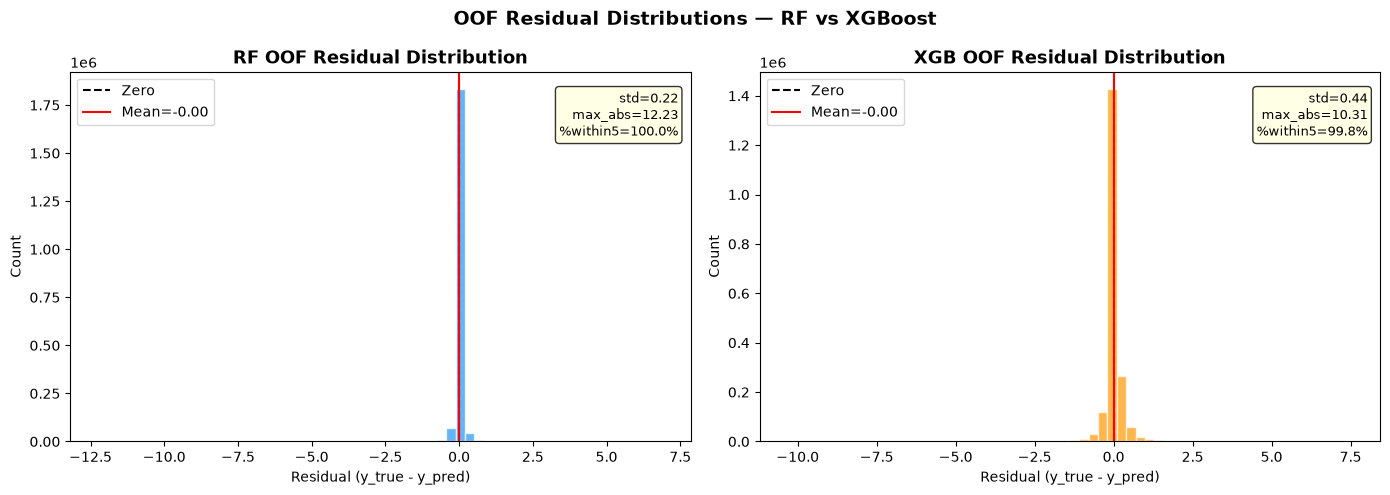

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, residuals, name, color in zip(
    axes, [residuals_rf, residuals_xgb], ['RF', 'XGB'], ['#2196F3', '#FF9800']
):
    ax.hist(residuals, bins=60, color=color, alpha=0.7, edgecolor='white')
    ax.axvline(0, color='black', lw=1.5, ls='--', label='Zero')
    ax.axvline(np.mean(residuals), color='red', lw=1.5, ls='-', label=f'Mean={np.mean(residuals):.2f}')
    ax.set_title(f'{name} OOF Residual Distribution', fontsize=13, fontweight='bold')
    ax.set_xlabel('Residual (y_true - y_pred)')
    ax.set_ylabel('Count')
    ax.legend(fontsize=10)
    stats = stats_rf if name == 'RF' else stats_xgb
    ax.text(
        0.98, 0.95,
        f"std={stats['std']:.2f}\nmax_abs={stats['max_abs']:.2f}\n%within5={stats['pct_within_5']:.1f}%",
        transform=ax.transAxes, ha='right', va='top', fontsize=9,
        bbox=dict(boxstyle='round,pad=0.3', facecolor='lightyellow', alpha=0.8)
    )

plt.suptitle('OOF Residual Distributions — RF vs XGBoost', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(paths['artifacts_dir'] / 'oof_residual_distributions.png', dpi=150, bbox_inches='tight')
plt.savefig(paths['secondary_output_dir'] / 'oof_residual_distributions.png', dpi=150, bbox_inches='tight')
plt.show()

## Section 3 — Residual MLP Architecture

In [11]:
hybrid_cfg = HybridConfig(
    input_dim=53,
    hidden_dims=[256, 128, 64],
    dropout_rate=0.2,
    use_batch_norm=True,
    rf_weight=0.4,
    xgb_weight=0.4,
    mlp_weight=0.2,
)

residual_net = ResidualMLPNet(hybrid_cfg).to(DEVICE)
print(residual_net.architecture_summary())

Architecture  : Hybrid_RF_XGB_ResidualMLP / ResidualMLPNet
Layer flow    : 54 → 256 → 128 → 64 → 1
BatchNorm     : True
Dropout       : 0.2
Parameters    : 56,193 trainable / 56,193 total


In [12]:
dummy_in = torch.zeros(4, 54).to(DEVICE)
dummy_out = residual_net(dummy_in)
print(f"Input shape: {dummy_in.shape}")
print(f"Output shape: {dummy_out.shape}")
assert dummy_out.shape == (4, 1), f"Expected (4,1), got {dummy_out.shape}"

Input shape: torch.Size([4, 54])
Output shape: torch.Size([4, 1])


## Section 4 — Residual MLP Training

In [13]:
base_train_pred = (oof_rf + oof_xgb) / 2.0
residuals_avg = y_train_np - base_train_pred

rf_val_pred = rf_model.predict(X_tree_val)
xgb_val_pred = xgb_model.predict(X_tree_val)
base_val_pred = (rf_val_pred + xgb_val_pred) / 2.0
residuals_val = y_val_np - base_val_pred

print(f"Train base preds: {base_train_pred.shape}")
print(f"Train residuals: mean={residuals_avg.mean():.4f}, std={residuals_avg.std():.4f}")
print(f"Val residuals: mean={residuals_val.mean():.4f}, std={residuals_val.std():.4f}")

Train base preds: (1973731,)
Train residuals: mean=-0.0012, std=0.2535
Val residuals: mean=-0.0010, std=0.2490


In [14]:
base_train_t = torch.from_numpy(base_train_pred.astype(np.float32))
res_train_t = torch.from_numpy(residuals_avg.astype(np.float32))
base_val_t = torch.from_numpy(base_val_pred.astype(np.float32))
res_val_t = torch.from_numpy(residuals_val.astype(np.float32))

train_res_loader, val_res_loader = build_residual_dataloaders(
    x_train_all, base_train_t, res_train_t,
    x_val_all, base_val_t, res_val_t,
    batch_size=1024,
)
print(f"Train loader batches: {len(train_res_loader)}")
print(f"Val loader batches: {len(val_res_loader)}")

Train loader batches: 1928
Val loader batches: 414


In [15]:
RESIDUAL_CKPT_PATH = paths['models_dir'] / 'residual_mlp_checkpoint.pt'

if RESIDUAL_CKPT_PATH.exists() and (paths['artifacts_dir'] / 'residual_training_history.json').exists():
    with open(paths['artifacts_dir'] / 'residual_training_history.json', 'r', encoding='utf-8') as f:
        res_history = json.load(f)
    ckpt = torch.load(RESIDUAL_CKPT_PATH, map_location=DEVICE, weights_only=False)
    residual_net.load_state_dict(ckpt['model_state_dict'])
    print(f"Loaded existing Residual MLP checkpoint (best val MAE: {res_history['best_val_mae']:.4f} @ epoch {res_history['best_epoch']})")
else:
    res_history = train_residual_mlp(
        model=residual_net,
        train_loader=train_res_loader,
        val_loader=val_res_loader,
        n_epochs=50,
        lr=1e-3,
        patience=10,
        device=DEVICE,
        save_path=RESIDUAL_CKPT_PATH,
    )
    with open(paths['artifacts_dir'] / 'residual_training_history.json', 'w', encoding='utf-8') as f:
        json.dump(res_history, f, indent=2)
    with open(paths['secondary_output_dir'] / 'residual_training_history.json', 'w', encoding='utf-8') as f:
        json.dump(res_history, f, indent=2)
    print(f"Trained Residual MLP: best val MAE {res_history['best_val_mae']:.4f} @ epoch {res_history['best_epoch']}")

Loaded existing Residual MLP checkpoint (best val MAE: 0.0713 @ epoch 49)


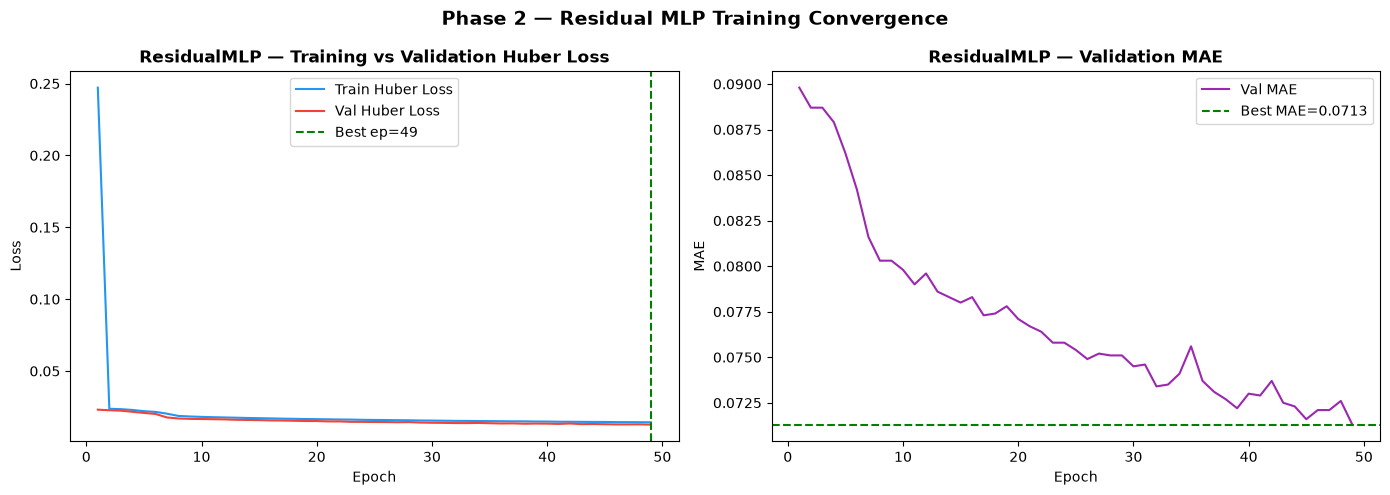

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
epochs = range(1, len(res_history['train_loss']) + 1)

axes[0].plot(epochs, res_history['train_loss'], label='Train Huber Loss', color='#2196F3')
axes[0].plot(epochs, res_history['val_loss'], label='Val Huber Loss', color='#F44336')
axes[0].axvline(res_history['best_epoch'], color='green', ls='--', lw=1.5, label=f"Best ep={res_history['best_epoch']}")
axes[0].set_title('ResidualMLP — Training vs Validation Huber Loss', fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()

axes[1].plot(epochs, res_history['val_mae'], label='Val MAE', color='#9C27B0')
axes[1].axhline(res_history['best_val_mae'], color='green', ls='--', lw=1.5, label=f"Best MAE={res_history['best_val_mae']:.4f}")
axes[1].set_title('ResidualMLP — Validation MAE', fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('MAE')
axes[1].legend()

plt.suptitle('Phase 2 — Residual MLP Training Convergence', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(paths['artifacts_dir'] / 'residual_mlp_training_curves.png', dpi=150, bbox_inches='tight')
plt.savefig(paths['secondary_output_dir'] / 'residual_mlp_training_curves.png', dpi=150, bbox_inches='tight')
plt.show()

## Section 5 — Hybrid Ensemble Evaluation

In [17]:
base_mlp, mlp_ckpt = load_model_checkpoint(paths['mlp_ckpt_path'], device=DEVICE)
base_mlp.eval()
print(f"Base MLP loaded: {mlp_ckpt.get('architecture_config', {}).get('name', 'MLP')}")

Base MLP loaded: MLP_Base


In [18]:
@torch.no_grad()
def get_mlp_preds(model, X_tensor, device, batch_size=16384):
    model.eval()
    all_preds = []
    n = len(X_tensor)
    for start in range(0, n, batch_size):
        batch = X_tensor[start:start + batch_size].to(device)
        p = model(batch).cpu().numpy().flatten()
        all_preds.append(p)
    return np.concatenate(all_preds, axis=0)

rf_val = rf_model.predict(X_tree_val)
xgb_val = xgb_model.predict(X_tree_val)
mlp_val = get_mlp_preds(base_mlp, x_val_all, DEVICE)

rf_test = rf_model.predict(X_tree_test)
xgb_test = xgb_model.predict(X_tree_test)
mlp_test = get_mlp_preds(base_mlp, x_test_all, DEVICE)

base_val_pred_avg = (rf_val + xgb_val) / 2.0
base_test_pred_avg = (rf_test + xgb_test) / 2.0

print(f"Val  — RF: {rf_val.shape}, XGB: {xgb_val.shape}, MLP: {mlp_val.shape}")
print(f"Test — RF: {rf_test.shape}, XGB: {xgb_test.shape}, MLP: {mlp_test.shape}")

Val  — RF: (422943,), XGB: (422943,), MLP: (422943,)
Test — RF: (422943,), XGB: (422943,), MLP: (422943,)


In [19]:
weighted_ens = WeightedEnsemble(rf_weight=0.4, xgb_weight=0.4, mlp_weight=0.2)
we_val = weighted_ens.predict(rf_val, xgb_val, mlp_val)
we_test = weighted_ens.predict(rf_test, xgb_test, mlp_test)
print(f"Weighted Ensemble — Val: {we_val.shape}, Test: {we_test.shape}")

Weighted Ensemble — Val: (422943,), Test: (422943,)


In [20]:
hybrid_model = HybridEnsemble(hybrid_cfg).to(DEVICE)
hybrid_model.residual_net.load_state_dict(residual_net.state_dict())
hybrid_model.eval()

hybrid_val = hybrid_model.predict_numpy(x_val_all.numpy(), base_val_pred_avg, device=DEVICE)
hybrid_test = hybrid_model.predict_numpy(x_test_all.numpy(), base_test_pred_avg, device=DEVICE)
print(f"Hybrid Ensemble — Val: {hybrid_val.shape}, Test: {hybrid_test.shape}")

Hybrid Ensemble — Val: (422943,), Test: (422943,)


In [21]:
def eval_metrics(y_true, y_pred, label, split):
    m = compute_regression_metrics(y_true, y_pred)
    return {'Model': label, 'Split': split, 'MAE': m['mae'], 'RMSE': m['rmse'], 'R2': m['r2']}

rows = []
for split, y_true, preds_dict in [
    ('Val', y_val_np, {'RF': rf_val, 'XGB': xgb_val, 'Base Tree (RF+XGB)': base_val_pred_avg, 'MLP (base)': mlp_val, 'Weighted Ensemble': we_val, 'Hybrid (RF+XGB+ResidualMLP)': hybrid_val}),
    ('Test', y_test_np, {'RF': rf_test, 'XGB': xgb_test, 'Base Tree (RF+XGB)': base_test_pred_avg, 'MLP (base)': mlp_test, 'Weighted Ensemble': we_test, 'Hybrid (RF+XGB+ResidualMLP)': hybrid_test}),
]:
    for model_name, preds in preds_dict.items():
        rows.append(eval_metrics(y_true, preds, model_name, split))

metrics_df = pd.DataFrame(rows)
metrics_df[['MAE', 'RMSE', 'R2']] = metrics_df[['MAE', 'RMSE', 'R2']].round(4)
print(metrics_df.to_string(index=False))

                      Model Split    MAE   RMSE     R2
                         RF   Val 0.0521 0.2081 0.9999
                        XGB   Val 0.1611 0.4372 0.9994
         Base Tree (RF+XGB)   Val 0.0902 0.2490 0.9998
                 MLP (base)   Val 1.3767 1.6685 0.9911
          Weighted Ensemble   Val 0.3091 0.4165 0.9994
Hybrid (RF+XGB+ResidualMLP)   Val 0.0713 0.1713 0.9999
                         RF  Test 0.0514 0.2016 0.9999
                        XGB  Test 0.1614 0.4364 0.9994
         Base Tree (RF+XGB)  Test 0.0900 0.2464 0.9998
                 MLP (base)  Test 1.3800 1.6720 0.9910
          Weighted Ensemble  Test 0.3096 0.4155 0.9994
Hybrid (RF+XGB+ResidualMLP)  Test 0.0710 0.1678 0.9999


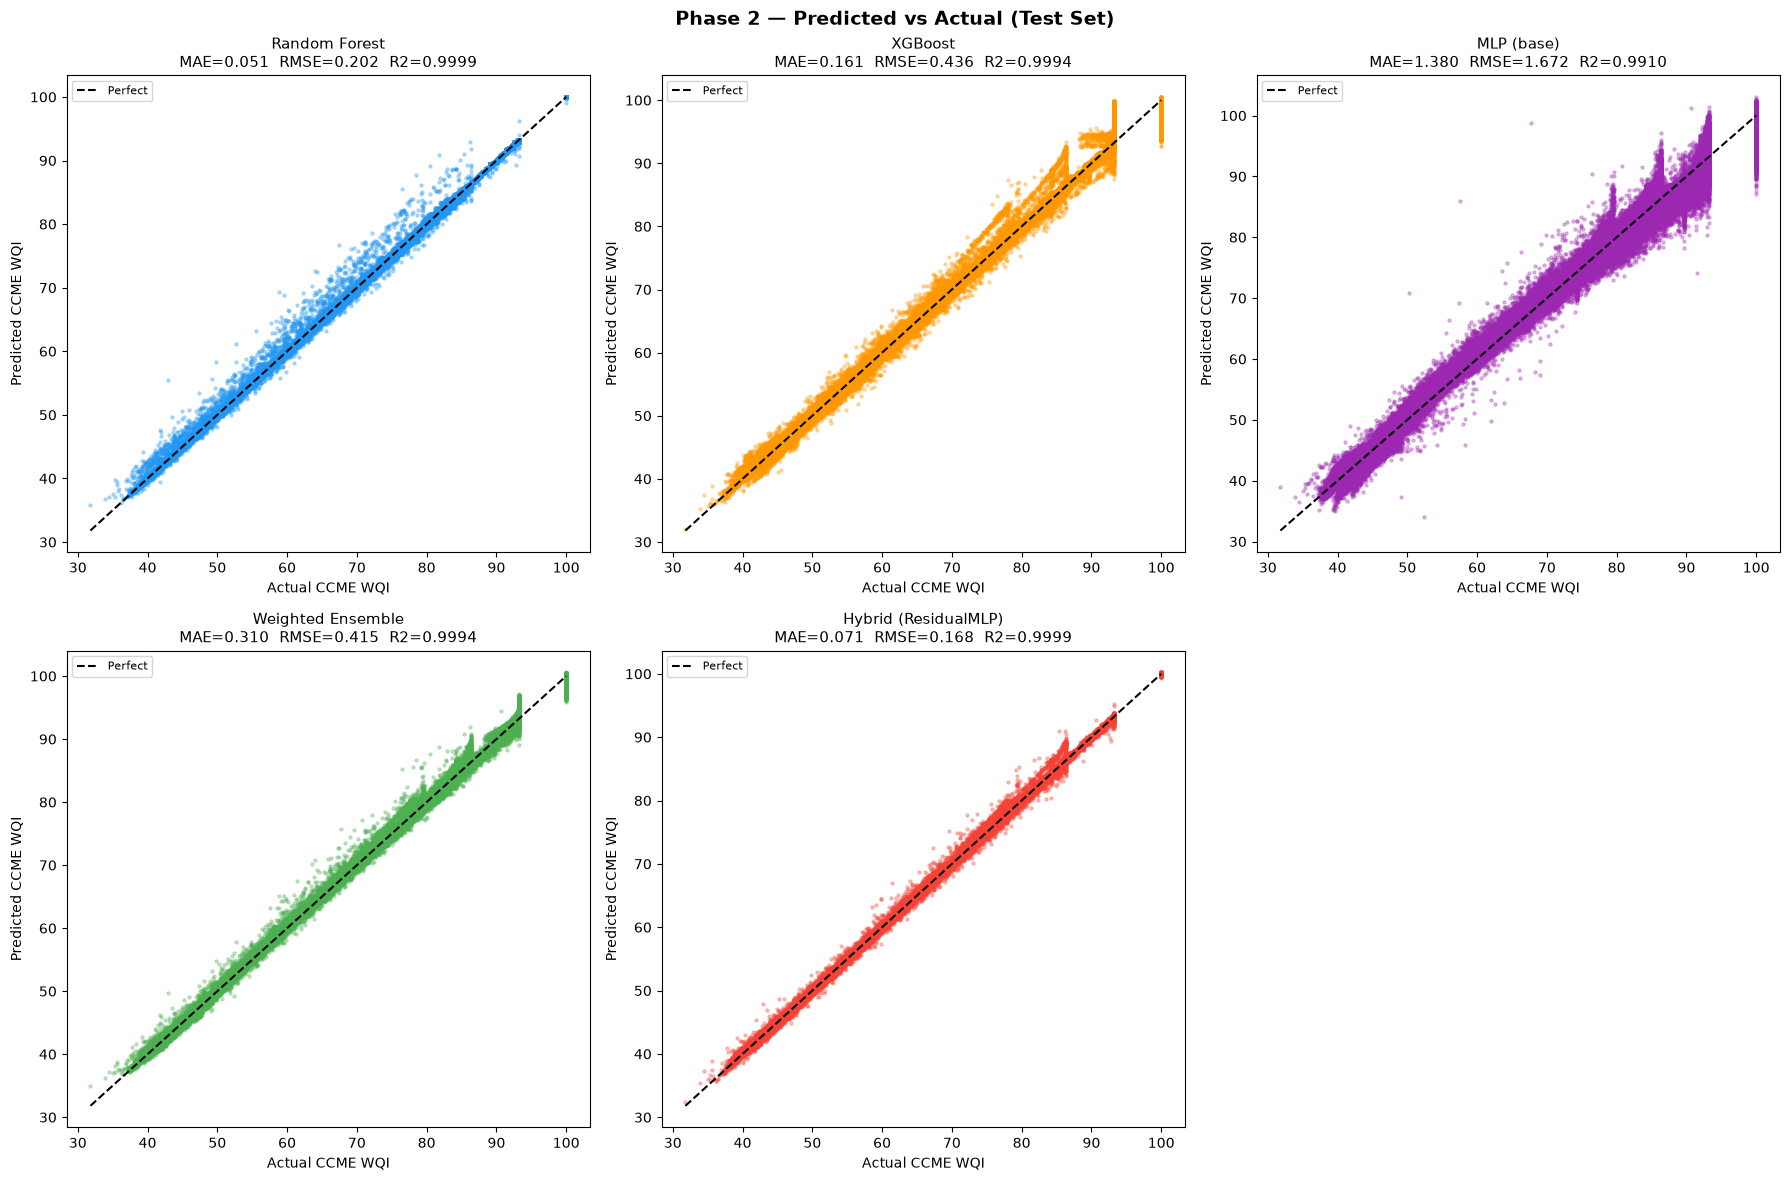

In [22]:
test_preds_all = {
    'Random Forest': rf_test,
    'XGBoost': xgb_test,
    'MLP (base)': mlp_test,
    'Weighted Ensemble': we_test,
    'Hybrid (ResidualMLP)': hybrid_test,
}

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()
colors = ['#2196F3', '#FF9800', '#9C27B0', '#4CAF50', '#F44336']

for ax, (model_name, preds), color in zip(axes, test_preds_all.items(), colors):
    m = compute_regression_metrics(y_test_np, preds)
    ax.scatter(y_test_np, preds, alpha=0.3, s=5, color=color, rasterized=True)
    min_v, max_v = y_test_np.min(), y_test_np.max()
    ax.plot([min_v, max_v], [min_v, max_v], 'k--', lw=1.5, label='Perfect')
    ax.set_title(f"{model_name}\nMAE={m['mae']:.3f}  RMSE={m['rmse']:.3f}  R2={m['r2']:.4f}", fontsize=11)
    ax.set_xlabel('Actual CCME WQI')
    ax.set_ylabel('Predicted CCME WQI')
    ax.legend(fontsize=8)

axes[-1].set_visible(False)
plt.suptitle('Phase 2 — Predicted vs Actual (Test Set)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(paths['artifacts_dir'] / 'hybrid_scatter_plots.png', dpi=150, bbox_inches='tight')
plt.savefig(paths['secondary_output_dir'] / 'hybrid_scatter_plots.png', dpi=150, bbox_inches='tight')
plt.show()

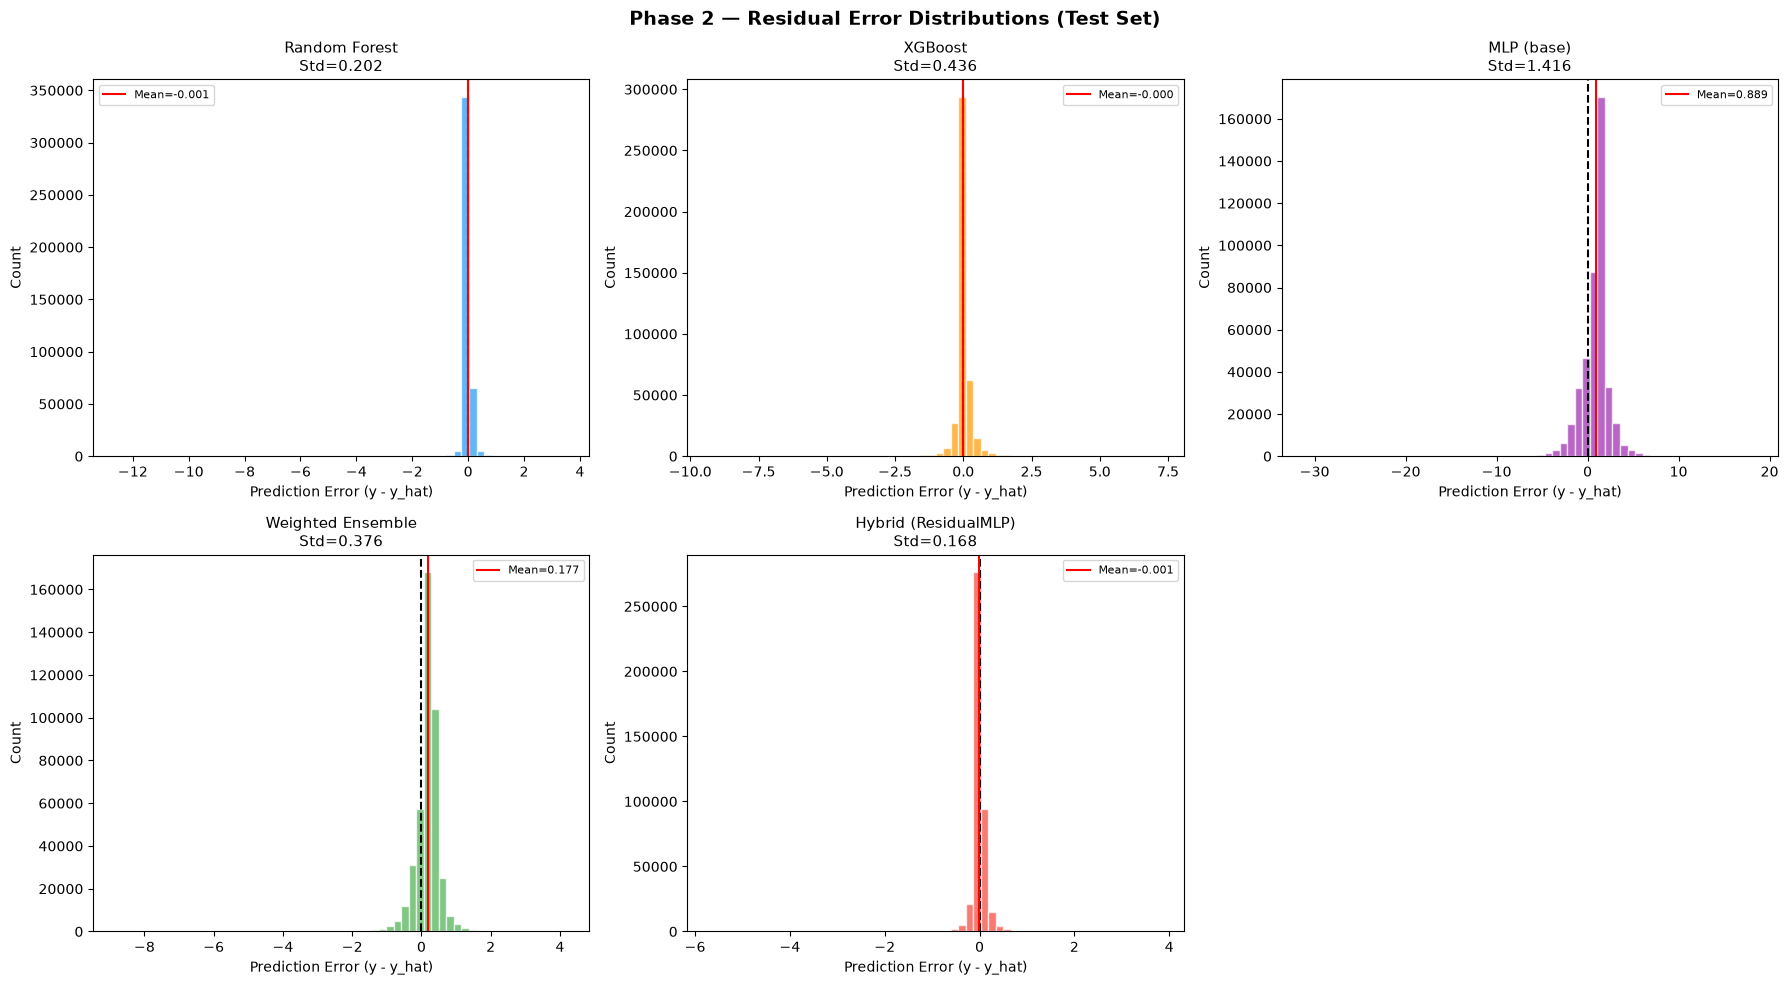

In [23]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for ax, (model_name, preds), color in zip(axes, test_preds_all.items(), colors):
    errors = y_test_np - preds
    ax.hist(errors, bins=60, color=color, alpha=0.7, edgecolor='white')
    ax.axvline(0, color='black', lw=1.5, ls='--')
    ax.axvline(np.mean(errors), color='red', lw=1.5, ls='-', label=f'Mean={np.mean(errors):.3f}')
    ax.set_title(f"{model_name}\nStd={np.std(errors):.3f}", fontsize=11)
    ax.set_xlabel('Prediction Error (y - y_hat)')
    ax.set_ylabel('Count')
    ax.legend(fontsize=8)

axes[-1].set_visible(False)
plt.suptitle('Phase 2 — Residual Error Distributions (Test Set)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(paths['artifacts_dir'] / 'hybrid_residual_plots.png', dpi=150, bbox_inches='tight')
plt.savefig(paths['secondary_output_dir'] / 'hybrid_residual_plots.png', dpi=150, bbox_inches='tight')
plt.show()

## Section 6 — Model Export and Summary

In [24]:
with open(paths['artifacts_dir'] / 'hybrid_config.json', 'w', encoding='utf-8') as f:
    json.dump(hybrid_cfg.to_dict(), f, indent=2)
with open(paths['secondary_output_dir'] / 'hybrid_config.json', 'w', encoding='utf-8') as f:
    json.dump(hybrid_cfg.to_dict(), f, indent=2)

with open(paths['artifacts_dir'] / 'weighted_ensemble_weights.json', 'w', encoding='utf-8') as f:
    json.dump(weighted_ens.to_dict(), f, indent=2)
with open(paths['secondary_output_dir'] / 'weighted_ensemble_weights.json', 'w', encoding='utf-8') as f:
    json.dump(weighted_ens.to_dict(), f, indent=2)

test_metrics_hybrid = compute_regression_metrics(y_test_np, hybrid_test)
save_hybrid_checkpoint(
    model=hybrid_model,
    config=hybrid_cfg,
    path=paths['models_dir'] / 'hybrid_ensemble_checkpoint.pt',
    metadata={
        'best_val_mae': float(res_history['best_val_mae']),
        'test_mae': test_metrics_hybrid['mae'],
        'test_rmse': test_metrics_hybrid['rmse'],
        'test_r2': test_metrics_hybrid['r2'],
    },
)

test_preds_df = pd.DataFrame({
    'y_true': y_test_np,
    'rf_pred': rf_test,
    'xgb_pred': xgb_test,
    'base_tree_pred': base_test_pred_avg,
    'mlp_pred': mlp_test,
    'weighted_ensemble': we_test,
    'hybrid_residual_mlp': hybrid_test,
})
val_preds_df = pd.DataFrame({
    'y_true': y_val_np,
    'rf_pred': rf_val,
    'xgb_pred': xgb_val,
    'base_tree_pred': base_val_pred_avg,
    'mlp_pred': mlp_val,
    'weighted_ensemble': we_val,
    'hybrid_residual_mlp': hybrid_val,
})

test_preds_df.to_parquet(paths['artifacts_dir'] / 'hybrid_test_predictions.parquet', index=False)
test_preds_df.to_parquet(paths['secondary_output_dir'] / 'hybrid_test_predictions.parquet', index=False)
val_preds_df.to_parquet(paths['artifacts_dir'] / 'hybrid_val_predictions.parquet', index=False)
val_preds_df.to_parquet(paths['secondary_output_dir'] / 'hybrid_val_predictions.parquet', index=False)

metrics_df.to_csv(paths['artifacts_dir'] / 'hybrid_metrics_comparison.csv', index=False)
metrics_df.to_csv(paths['secondary_output_dir'] / 'hybrid_metrics_comparison.csv', index=False)
print('Saved all hybrid model artifacts.')

✓ Hybrid checkpoint saved → /Users/amansoni/Documents/Development/Personal Projects/Semester_5_AML_DL/Phase_2_Deep_Learning/models/hybrid_ensemble_checkpoint.pt
Saved all hybrid model artifacts.


In [25]:
test_rows = metrics_df[metrics_df['Split'] == 'Test'].copy()
print(test_rows[['Model', 'MAE', 'RMSE', 'R2']].to_string(index=False))
best_row = test_rows.loc[test_rows['MAE'].idxmin()]
print(f"Best model by MAE: {best_row['Model']} (MAE={best_row['MAE']:.4f})")

                      Model    MAE   RMSE     R2
                         RF 0.0514 0.2016 0.9999
                        XGB 0.1614 0.4364 0.9994
         Base Tree (RF+XGB) 0.0900 0.2464 0.9998
                 MLP (base) 1.3800 1.6720 0.9910
          Weighted Ensemble 0.3096 0.4155 0.9994
Hybrid (RF+XGB+ResidualMLP) 0.0710 0.1678 0.9999
Best model by MAE: RF (MAE=0.0514)
